# 物体占位符:objptr_v1(第 2 层 / 第 4 层 / 两层)

**问题**:之前 6 个模型在选择题上都不看场景。答这类题要连做几步(找到物体 → 换算视角 → 比较),而损失只奖励最后一步,所以第一步从来学不会。这组实验单独奖励第一步:找到物体。

**做法**(底座 dinotxt_enc_v1:dino.txt 的 patch 作场景 token,8 帧 × 88 格 = 704 格):

- 题目里每个物体名配一个占位符 token,数量不固定。
- **初始化**:占位符 = 相关场景 token 的加权平均 + 物体名的 dino.txt 文本向量 + 类型向量。权重来自文本向量与各格 patch 特征的相似度(标准化后 softmax,起始平均约 8 格)。
- **定位损失**:predictor 某一层之后,占位符的隐状态要在 704 个格子里选中物体所在的格子。正例是物体真实中心投影到的格子(每帧一个),只取中心在画面内且未被遮挡的帧;正例周围一圈、以及被遮挡投影周围一圈不计入。
- 答案损失不变;答案从题目 token 和占位符的输出一起取平均读出。

| 实验 | 定位损失所在层 |
|---|---|
| objptr_v1_l2 | 第 2 层 |
| objptr_v1_l4 | 第 4 层 |
| objptr_v1 | 第 2 层和第 4 层 |

三者数据、步数(6870 步,3 张卡,1 个 epoch)、初始权重相同。

**标签**:ground_v1 的真实物体中心,加上用深度图做的遮挡判断(表面比中心近 0.6 m 以上算遮挡)。训练集 714,592 个带标签的名字中 628,656 个(88%)至少在一帧可见;画面内的投影 15% 判为遮挡,5% 深度无效。

## 总结

- **定位学会了**:验证场景上指中率 33.0%(dino.txt 自己选)→ 约 71%,射线误差 0.51 m → 0.15 m。换场景掉到 2%,换成别的名字掉到 7%。
- **监督纠正了初始化的错误**:初始化指错的名字里约 61% 被纠正,不是在复制初始化。
- **第 2 层和第 4 层没有差别**,单层和两层也没有差别。
- **VSI-Bench 是目前最高,但仍不看场景**:test 39.4(之前最好 37.7),debiased 39.6(之前最好 36.8);真场景和换场景相同。
- **留出集第一次出现场景差距**:真场景比换场景高 2–5 个点,出现顺序题高 10–18 个点;相对方向题没有差距。
- **这个差距没有出现在 VSI-Bench 上**,原因未知。已排除答案格式和对照失效。
- **多跑 epoch 没有用**:验证指中率约 3,500 步后停在 70%,训练集到 88–90%。
- MMSI-Bench 未评测。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
load = lambda path: json.load(open(path))
RUNS = {"只第 2 层": "objptr_v1_l2", "只第 4 层": "objptr_v1_l4", "两层": "objptr_v1"}
EVAL = {k: load(f"../../{v}/results/eval_final.json") for k, v in RUNS.items()}
OLD = {"dinotxt_q_v1": load("../../dinotxt_q_v1/results/eval_final.json"),
       "dinotxt_enc_v1": load("../../dinotxt_enc_v1/results/eval_final.json")}
UNTRAINED = load("../results/eval_untrained.json")
MODES = {"real": "真场景", "shuffled": "换场景", "zero": "全零场景", "slots_swapped": "换成别的名字", "slots_none": "去掉占位符"}
MC = {"相对距离": ["object_rel_distance"],
      "相对方向": ["object_rel_direction_easy", "object_rel_direction_medium", "object_rel_direction_hard"],
      "路线规划": ["route_planning"], "出现顺序": ["obj_appearance_order"]}

def tasks(res, split):
    mc = res[f"vsibench_{split}_posed_f8"]
    out = {t: sum(100 * mc["type/" + k] for k in ks) / len(ks) for t, ks in MC.items()}
    return {**out, "4 任务平均": sum(out.values()) / 4}

## 1 VSI-Bench 选择题

带位姿的 ScanNet / ScanNet++ 部分:test 1,845 题,debiased 811 题。数字是 4 个任务的平均。每个任务 90–620 题,3 个点以内的差别不算数。

In [2]:
rows = {}
for split in ("test", "debiased"):
    for mode, label in MODES.items():
        rows[f"{split} {label}"] = {name: tasks(r[mode], split)["4 任务平均"] if mode in r else None
                                   for name, r in {**EVAL, **OLD}.items()}
pd.DataFrame(rows).T.astype(float).round(1)

,只第 2 层,只第 4 层,两层,dinotxt_q_v1,dinotxt_enc_v1
test 真场景,37.8,39.4,39.3,37.7,34.1
test 换场景,38.9,39.0,39.6,37.5,33.6
test 全零场景,30.5,31.7,30.0,36.7,32.2
test 换成别的名字,30.8,31.0,31.4,34.3,NaN
test 去掉占位符,29.6,28.6,24.5,28.5,NaN
debiased 真场景,37.2,39.6,39.2,35.4,36.3
debiased 换场景,37.9,39.5,40.0,35.1,37.4
debiased 全零场景,30.4,35.8,31.3,35.6,33.5
debiased 换成别的名字,30.1,31.4,30.8,32.1,NaN
debiased 去掉占位符,32.6,34.9,29.5,32.7,NaN


In [3]:
pd.DataFrame({f"{name} {MODES[m]}": tasks(r[m], "test") for name, r in EVAL.items() for m in ("real", "shuffled")}).round(1)

,只第 2 层 真场景,只第 2 层 换场景,只第 4 层 真场景,只第 4 层 换场景,两层 真场景,两层 换场景
相对距离,34.3,34.8,37.2,36.1,39.0,38.1
相对方向,35.7,34.7,32.7,34.7,33.6,33.3
路线规划,31.1,36.7,35.6,34.4,34.4,37.8
出现顺序,50.2,49.5,52.1,50.8,50.0,49.4
4 任务平均,37.8,38.9,39.4,39.0,39.3,39.6


## 2 定位

验证场景(训练没见过)上 8,439 个可见的名字。**指中** = 得分最高的格子是中心投影所在格子或其紧邻的 8 格(约 84 像素见方)。**射线误差** = 该格子的射线到物体中心的距离,取中位数。随机指中率 1.7%。

之前说的 dino.txt 62% 是"落在 3D 框内",标准不同;这里的起点是 33.0%。

In [4]:
def pointing(res, group="all"):
    p = res["pointer"][group]
    return {k: (100 * v if k.endswith("acc") else v) for k, v in p.items() if k[0] == "l"}

base = UNTRAINED["real"]["pointer"]["all"]
rows = {"起点(dino.txt 自己选,不训练)": {"指中率": 100 * base["init_acc"], "射线误差 m": base["init_error_m"]}}
for name, r in EVAL.items():
    for layer in (2, 4):
        if f"l{layer}_acc" in r["real"]["pointer"]["all"]:
            p = r["real"]["pointer"]["all"]
            rows[f"{name},第 {layer} 层"] = {"指中率": 100 * p[f"l{layer}_acc"], "射线误差 m": p[f"l{layer}_error_m"],
                **{MODES[m]: 100 * r[m]["pointer"]["all"][f"l{layer}_acc"] for m in ("shuffled", "zero", "slots_swapped")}}
pd.DataFrame(rows).T.round({"指中率": 1, "射线误差 m": 3, "换场景": 1, "全零场景": 1, "换成别的名字": 1})

,指中率,射线误差 m,换场景,全零场景,换成别的名字
"起点(dino.txt 自己选,不训练)",33.0,0.510,NaN,NaN,NaN
"只第 2 层,第 2 层",70.8,0.149,2.1,0.6,7.1
"只第 4 层,第 4 层",71.4,0.148,2.3,0.6,7.3
"两层,第 2 层",70.6,0.149,2.3,0.6,7.3
"两层,第 4 层",71.1,0.148,2.1,0.6,7.5


按初始化的对错拆开(初始化指对 2,783 个,指错 5,656 个),以及按数据来源:

In [5]:
groups = {"untrained_choice:right": "初始化指对的", "untrained_choice:wrong": "初始化指错的",
          "subset:scannet": "ScanNet", "subset:scannetpp": "ScanNet++"}
pd.DataFrame({name: {label: max(v for k, v in pointing(r["real"], g).items() if k.endswith("acc"))
                     for g, label in groups.items()} for name, r in EVAL.items()}).round(1)

,只第 2 层,只第 4 层,两层
初始化指对的,91.3,92.2,91.8
初始化指错的,60.7,61.2,61.3
ScanNet,75.8,76.8,76.5
ScanNet++,64.1,64.1,63.9


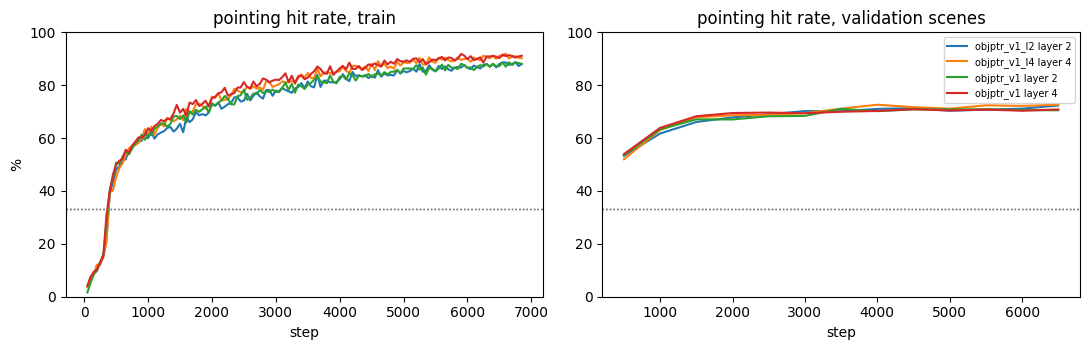

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, folder in RUNS.items():
    log = [json.loads(l) for l in open(f"../../{folder}/results/hardneg_log.jsonl")]
    for ax, prefix, title in ((axes[0], "ptr_", "train"), (axes[1], "val_ptr_", "validation scenes")):
        rows = [d for d in log if any(k.startswith(prefix + "l") for k in d)]
        for layer in (2, 4):
            key = f"{prefix}l{layer}_acc"
            if rows and key in rows[0]:
                ax.plot([d["step"] for d in rows], [100 * d[key] for d in rows], label=f"{folder} layer {layer}")
        ax.set_title(f"pointing hit rate, {title}"); ax.set_xlabel("step"); ax.set_ylim(0, 100)
        ax.axhline(33, color="gray", ls=":", lw=1)
axes[1].legend(fontsize=7); axes[0].set_ylabel("%"); plt.tight_layout()

虚线是不训练的起点(33%)。验证曲线约 3,500 步后不再上升,训练集仍在涨:瓶颈是场景数量(约 1,200 个),不是训练时长。

## 3 留出集(次要对照)

与训练同分布、场景未见过,6,786 题,长答案格式。每格是 真场景 / 换场景。

In [7]:
TYPES = {"long/all": "全部", "long/vsi590k/appearance_order": "出现顺序(VSI-590K)", "long/spar/appearance_order": "出现顺序(SPAR)",
         "long/vsi590k/relative_distance_object": "相对距离", "long/vsi590k/relative_count": "相对计数",
         "long/vsi590k/relative_direction_object": "相对方向", "long/vsi590k/relative_size_object": "相对大小",
         "long/spar/spatial_imagination_oc_video_hard": "空间想象(物体–相机)",
         "long/spar/spatial_imagination_oo_video_hard": "空间想象(物体–物体)"}
cell = lambda r, k: f'{100 * r["real"]["holdout"][k]["acc"]:.1f} / {100 * r["shuffled"]["holdout"][k]["acc"]:.1f}'
pd.DataFrame({name: {label: cell(r, k) for k, label in TYPES.items()} for name, r in {**EVAL, "dinotxt_q_v1": OLD["dinotxt_q_v1"]}.items()})

,只第 2 层,只第 4 层,两层,dinotxt_q_v1
全部,48.0 / 45.8,49.6 / 45.6,49.2 / 44.6,47.5 / 47.0
出现顺序(VSI-590K),48.4 / 46.7,53.0 / 43.2,52.7 / 35.1,47.9 / 47.2
出现顺序(SPAR),43.3 / 36.0,46.0 / 34.7,44.9 / 32.9,41.9 / 40.4
相对距离,47.3 / 41.5,51.0 / 45.2,48.0 / 41.9,44.5 / 44.2
相对计数,51.9 / 42.9,50.6 / 46.1,59.7 / 47.4,61.0 / 53.2
相对方向,45.4 / 46.5,45.3 / 44.7,44.6 / 44.9,46.2 / 45.8
相对大小,86.0 / 84.2,85.3 / 84.3,85.4 / 85.0,86.2 / 85.8
空间想象(物体–相机),43.5 / 43.4,43.3 / 42.6,46.1 / 45.2,42.1 / 42.5
空间想象(物体–物体),21.7 / 22.9,24.2 / 23.8,22.1 / 23.0,21.5 / 22.1


## 4 结论与下一步

1. 占位符思路成立:初始化负责指代,监督把指中率从 33% 提到 71%,并且依赖场景和名字。
2. 监督放在第 2 层还是第 4 层对定位没有影响;留出集上的场景差距在第 4 层和两层时更大。后续用第 4 层或两层。
3. 定位之后的步骤仍没有奖励:相对方向题(需要换算视角)在留出集上真假场景没有差别。
4. 留出集上的收益没有到达 VSI-Bench。下一步先查这一点,例如给 VSI-Bench 的场景补位置标签,看占位符在那里指得准不准;然后再决定是否加视角占位符。

**文件**:代码 `jepa3d/pointer.py`、`jepa3d/tools/add_visibility.py`;配置 `jepa3d/configs/objptr_v1{,_l2,_l4}.yaml`;标签 `experiments/objptr_v1/data/`;结果 `experiments/objptr_v1{,_l2,_l4}/results/eval_final.json`;作业 13768(两层)、13769(第 4 层)、13770(第 2 层),各约 3 小时 25 分。